In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import statsmodels.formula.api as smf

from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import classification_report, roc_curve, auc, recall_score, precision_recall_curve
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix, precision_score, hamming_loss
from sklearn.metrics import brier_score_loss, average_precision_score

import copy 
import torch
import torch.nn as nn

In [2]:
import pickle
with open('balanced_data.pkl', 'rb') as b:
    data = pickle.load(b)

X_res_sk = data['X_res_stroke']
y_res_sk = data['y_res_stroke']
X_res_db = data['X_res_diab']
y_res_db = data['y_res_diab']
X_res_cn = data['X_res_can']
y_res_cn = data['y_res_can']       
X_res_ha = data['X_res_ha']
y_res_ha = data['y_res_ha']    

X_val = data['X_val'] 
y_val = data['y_val']   

X_test = data['X_test']
y_test = data['y_test']

X_bal=data['X_bal']
y_bal=data['y_bal']
    

In [3]:
y_test=y_test.rename(columns=
              {'heart_attack' : 'HA'})
y_bal=y_bal.rename(columns=
              {'heart_attack' : 'HA'})
y_val=y_val.rename(columns=
              {'heart_attack' : 'HA'})

In [4]:
scaler = MinMaxScaler()
X_train_st = scaler.fit_transform(X_bal)
X_val_st   = scaler.transform(X_val)
X_test_st = scaler.transform(X_test)

x_train_t = torch.tensor(X_train_st, dtype=torch.float32)
y_train_t = torch.tensor(y_bal.values, dtype=torch.float32)

x_val_t   = torch.tensor(X_val_st, dtype=torch.float32)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32)

x_test_t  = torch.tensor(X_test_st, dtype=torch.float32)

In [5]:
def youden_threshold(y_true_col, y_prob_col):
    fpr, tpr, thresholds = roc_curve(y_true_col, y_prob_col)
    return thresholds[np.argmax(tpr - fpr)]

***MLP MODEL***

In [6]:

class MLP(nn.Module):
    def __init__(self,n_features,n_outputs, M):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(n_features, M),
            nn.ReLU(),
            nn.Linear(M, M),
            nn.ReLU(),
            nn.Linear(M,n_outputs),
        )
    def forward(self,x):
        return self.model(x)
    

pos_weight = torch.tensor([
    (y_bal[col] == 0).sum() / (y_bal[col] == 1).sum()
    for col in y_bal.columns
], dtype=torch.float32)

loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
n_features = X_train_st.shape[1]
n_outputs = y_bal.shape[1]



***TUNING LAMBDA AND SIZE (M)***

In [8]:
torch.manual_seed(1234)

lambdas    = np.logspace(-5, -3, 4)
M_val      = [16, 32, 64]
n_epochs   = 1000
n_restarts = 5
tuning_results = []

for lam in lambdas:
    for M in M_val:

        best_misc  = np.inf
        best_model = None

        for h in range(n_restarts):
            model = MLP(n_features, n_outputs, M)
            opt   = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=lam)

            for epoch in range(n_epochs):
                model.train()
                opt.zero_grad()
                loss = loss_fn(model(x_train_t), y_train_t)
                loss.backward()
                opt.step()

            # Best restart by validation misclassification
            model.eval()
            with torch.no_grad():
                y_prob_val_h = torch.sigmoid(model(x_val_t)).numpy()

            errors_h = []
            for i, col in enumerate(y_val.columns):
                thr      = youden_threshold(y_val[col].values, y_prob_val_h[:, i])
                y_pred_i = (y_prob_val_h[:, i] >= thr).astype(int)
                errors_h.append((y_pred_i != y_val[col].values).mean())
            misc_h = np.mean(errors_h)

            if misc_h < best_misc:
                best_misc  = misc_h
                best_model = copy.deepcopy(model)

        best_model.eval()
        with torch.no_grad():
            y_prob_val = torch.sigmoid(best_model(x_val_t)).numpy()

        errors = []
        for i, col in enumerate(y_val.columns):
            thr      = youden_threshold(y_val[col].values, y_prob_val[:, i])
            y_pred_i = (y_prob_val[:, i] >= thr).astype(int)
            errors.append((y_pred_i != y_val[col].values).mean())
        misc = np.mean(errors)

        print(f"lambda={lam:.2e}  M={M}  misc={misc:.4f}")
        tuning_results.append((lam, M, misc))

best_lam, best_M, best_misclass = min(tuning_results, key=lambda x: x[2])
print(f"\nMiglior lambda={best_lam:.2e}, M={best_M}, Misclassification={best_misclass:.4f}")


lambda=1.00e-05  M=16  misc=0.3569
lambda=1.00e-05  M=32  misc=0.4063
lambda=1.00e-05  M=64  misc=0.3991
lambda=4.64e-05  M=16  misc=0.3659
lambda=4.64e-05  M=32  misc=0.3715
lambda=4.64e-05  M=64  misc=0.3458
lambda=2.15e-04  M=16  misc=0.3607
lambda=2.15e-04  M=32  misc=0.3287
lambda=2.15e-04  M=64  misc=0.3418
lambda=1.00e-03  M=16  misc=0.3806
lambda=1.00e-03  M=32  misc=0.3497
lambda=1.00e-03  M=64  misc=0.3712

Miglior lambda=2.15e-04, M=32, Misclassification=0.3287


In [9]:
best_misc_final = np.inf
model_final     = None
torch.manual_seed(1234)

for h in range(n_restarts):
    model = MLP(n_features, n_outputs, best_M)
    opt   = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=best_lam)

    for epoch in range(n_epochs):
        model.train()
        opt.zero_grad()
        loss = loss_fn(model(x_train_t), y_train_t)
        loss.backward()
        opt.step()

    model.eval()
    with torch.no_grad():
        y_prob_val_h = torch.sigmoid(model(x_val_t)).numpy()

    errors_h = []
    for i, col in enumerate(y_val.columns):
        thr      = youden_threshold(y_val[col].values, y_prob_val_h[:, i])
        y_pred_i = (y_prob_val_h[:, i] >= thr).astype(int)
        errors_h.append((y_pred_i != y_val[col].values).mean())
    misc_h = np.mean(errors_h)

    if misc_h < best_misc_final:
        best_misc_final = misc_h
        model_final     = copy.deepcopy(model)

print(f'Best misc finale: {best_misc_final:.4f}')

Best misc finale: 0.3287


In [11]:
model_final.eval()
with torch.no_grad():
    y_prob_val = torch.sigmoid(model_final(x_val_t)).numpy()  # BCEWithLogitsLoss outputs logits: apply sigmoid to get probabilities

# Youden index threshold (no Bayes rule) on the validation set
best_thresholds_mlp = {}
for i, col in enumerate(y_val.columns):
    fpr, tpr, thresholds = roc_curve(y_val[col], y_prob_val[:, i])
    best_t = thresholds[np.argmax(tpr - fpr)]
    best_thresholds_mlp[col] = best_t
    print(f"{col}: threshold = {best_t:.3f}")

with torch.no_grad():
    y_prob = torch.sigmoid(model_final(x_test_t)).numpy()

results_mlp = {}
for i, col in enumerate(y_test.columns):
    y_pred_i = (y_prob[:, i] >= best_thresholds_mlp[col]).astype(int)
    
    precision, recall, _ = precision_recall_curve(y_test[col].values, y_prob[:,i])
    
    results_mlp[col] = {
        'f1'       : f1_score(y_test[col], y_pred_i),
        'precision': precision_score(y_test[col],y_pred_i),
        'auc'      : roc_auc_score(y_test[col], y_prob[:, i]),
        'misc'     : (y_pred_i != y_test[col].values).mean(),
        'sens' : recall_score(y_test[col].values, y_pred_i),
        'auc-pr': auc(recall, precision),
        'confusion': confusion_matrix(y_test[col], y_pred_i),
        "brier": brier_score_loss(y_test[col].values, y_prob[:, i]),
        'threshold': best_thresholds_mlp[col]
    }

y_pred_multi_ml = np.zeros_like(y_test.values)
for i, col in enumerate(y_test.columns):
    y_pred_multi_ml[:, i] = (y_prob[:, i] >= best_thresholds_mlp[col]).astype(int)


macro_auc = np.mean([
    roc_auc_score(y_test[col].values, y_prob[:, i])
    for i, col in enumerate(y_test.columns)
])

macro_auc_pr = np.mean([
    average_precision_score(y_test[col].values, y_prob[:, i])
    for i, col in enumerate(y_test.columns)
])

macro_f1 = f1_score(y_test.values, y_pred_multi_ml, average='macro')

hamming = hamming_loss(y_test.values, y_pred_multi_ml)

brier_mean = np.mean([
    brier_score_loss(y_test[col].values, y_prob[:, i])
    for i, col in enumerate(y_test.columns)
])

results_mlp["MacroF1"] = macro_f1
results_mlp["Hamming"] = hamming
results_mlp["Brier_mean"] = brier_mean
results_mlp["MacroAUC"] = macro_auc
results_mlp["MacroAUC_PR"] = macro_auc_pr

print(pd.DataFrame({k: v for k, v in results_mlp.items() if k not in ['confusion','threshold']}).T)
for col, res in results_mlp.items():
    if isinstance(res,dict):
        print(f"\n{col}:\n", res["confusion"])

diabetes: threshold = 0.534
stroke: threshold = 0.308
HA: threshold = 0.516
cancer: threshold = 0.297
                   f1 precision       auc      misc      sens    auc-pr  \
diabetes     0.452917  0.324556  0.828891  0.258295   0.74924  0.445439   
stroke       0.114833  0.062536  0.745654  0.361093  0.701299  0.085671   
HA           0.334352  0.219736   0.74457  0.330731  0.698905  0.270532   
cancer       0.112568  0.063074  0.612108  0.352201  0.522843  0.058422   
MacroF1      0.253667  0.253667  0.253667  0.253667  0.253667  0.253667   
Hamming       0.32558   0.32558   0.32558   0.32558   0.32558   0.32558   
Brier_mean   0.150853  0.150853  0.150853  0.150853  0.150853  0.150853   
MacroAUC     0.732806  0.732806  0.732806  0.732806  0.732806  0.732806   
MacroAUC_PR  0.216275  0.216275  0.216275  0.216275  0.216275  0.216275   

                              confusion     brier threshold  
diabetes     [[2927, 1026], [165, 493]]  0.180878  0.534428  
stroke        [[2838, 1

In [12]:
def expected_calibration_error(y_true, y_prob, n_bins=10):
    quantiles = np.percentile(y_prob, np.linspace(0, 100, n_bins + 1))
    ece = 0
    n = len(y_prob)
    for b in range(n_bins):
        mask = (y_prob >= quantiles[b]) & (y_prob < quantiles[b+1])
        if mask.sum() > 0:
            acc = y_true[mask].mean()  # observed fraction of positives
            conf = y_prob[mask].mean()  # mean predicted probability
            ece += mask.mean() * abs(acc - conf)
    return ece

for i, col in enumerate(y_test.columns):
    ece = expected_calibration_error(
        y_test[col].values, 
        y_prob[:, i]
    )
    print(f'{col}: ECE = {ece:.4f}')
    results_mlp[col]["ece"] = ece


diabetes: ECE = 0.2603
stroke: ECE = 0.2328
HA: ECE = 0.2974
cancer: ECE = 0.2224


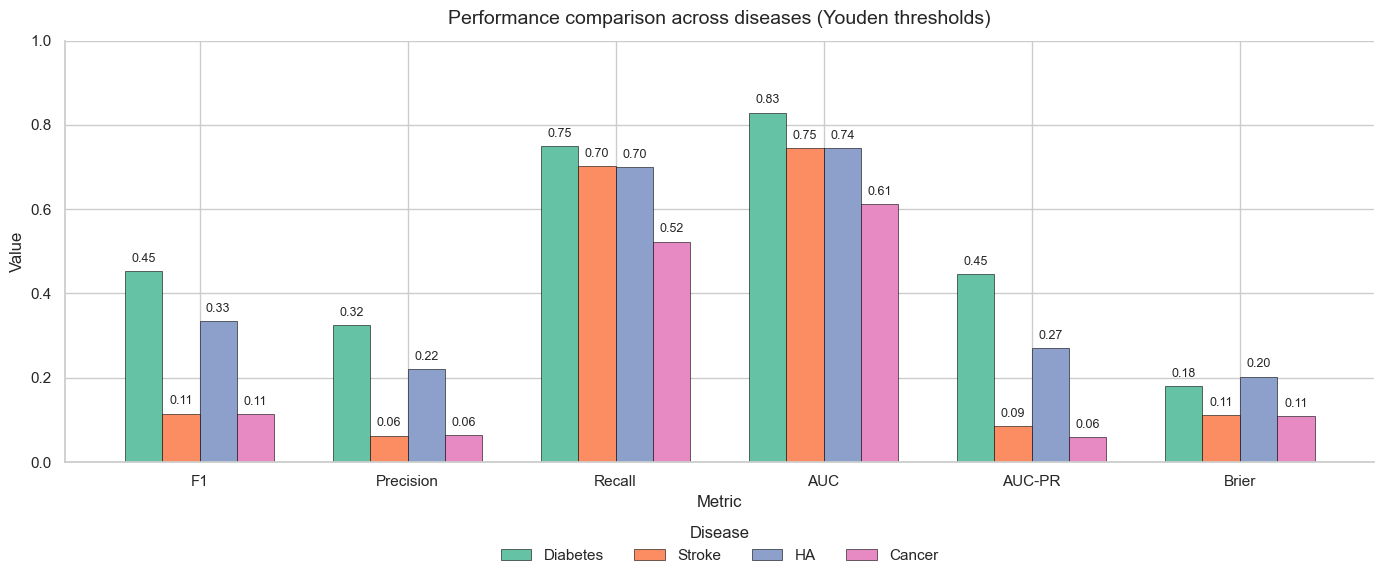

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

diseases = ['Diabetes', 'Stroke', 'HA', 'Cancer']

metric_map = {
    'F1'        : 'f1',
    'Precision' : 'precision',
    'Recall'    : 'sens',
    'AUC'       : 'auc',
    'AUC-PR'    : 'auc-pr',
    'Brier'     : 'brier'
}

metrics = list(metric_map.keys())

metric_df = pd.DataFrame({
    'Diabetes': [results_mlp['diabetes'][metric_map[m]] for m in metrics],
    'Stroke'  : [results_mlp['stroke'][metric_map[m]]   for m in metrics],
    'HA'      : [results_mlp['HA'][metric_map[m]]       for m in metrics],
    'Cancer'  : [results_mlp['cancer'][metric_map[m]]   for m in metrics],
}, index=metrics)

sns.set_theme(
    style="whitegrid",
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False
    }
)

palette = sns.color_palette("Set2", 4)

x = np.arange(len(metrics))
width = 0.18

fig, ax = plt.subplots(figsize=(14, 6))

for i, disease in enumerate(metric_df.columns):
    bars = ax.bar(
        x + i * width,
        metric_df[disease].values,
        width=width,
        label=disease,
        color=palette[i],
        edgecolor='black',
        linewidth=0.4
    )

    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h + 0.015,
            f"{h:.2f}",
            ha='center',
            va='bottom',
            fontsize=9
        )

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.set_ylabel("Value")
ax.set_xlabel("Metric")

ax.set_title(
    "Performance comparison across diseases (Youden thresholds)",
    fontsize=14,
    pad=12
)

ax.legend(
    title="Disease",
    ncol=4,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12)
)

plt.tight_layout()
plt.show()

In [14]:
import pickle

with open("results_mlp.pkl", "wb") as f:
    pickle.dump(results_mlp, f)